This notebook maps the taxi zones and theaters used in the analysis.

Load the taxi zone shapefile and the geocoded theater data.

In [9]:
import os
os.makedirs("../plots", exist_ok=True)

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.patches import Patch, Rectangle
from matplotlib.legend_handler import HandlerBase
zones = gpd.read_file("../data/taxi_zones/taxi_zones.shp") 
theaters_zones = pd.read_csv("../data/broadway_data/theaters_zones.csv")
theater_zone_ids = theaters_zones["LocationID"].dropna().astype(int).unique().tolist()
control_zone_id = zones.loc[zones["zone"] == "Murray Hill", "LocationID"].iloc[0]  # confirm column name matches your shapefile
manhattan = zones[zones["borough"] == "Manhattan"].copy()  # adjust column names to your shapefile schema
manhattan["highlight"] = "Other Manhattan"
manhattan.loc[manhattan["LocationID"].isin(theater_zone_ids), "highlight"] = "Theater District zones"
manhattan.loc[manhattan["LocationID"] == control_zone_id, "highlight"] = "Control zone (Murray Hill)"

theaters_gdf = gpd.GeoDataFrame(
    theaters_zones,
    geometry=gpd.points_from_xy(
        theaters_zones["longitude"],
        theaters_zones["latitude"]
    ),
    crs="EPSG:4326"
).to_crs(manhattan.crs)

Map showing the theater zones, the control zone, and each theater.

/tmp/ipykernel_100624/3625410446.py:290: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


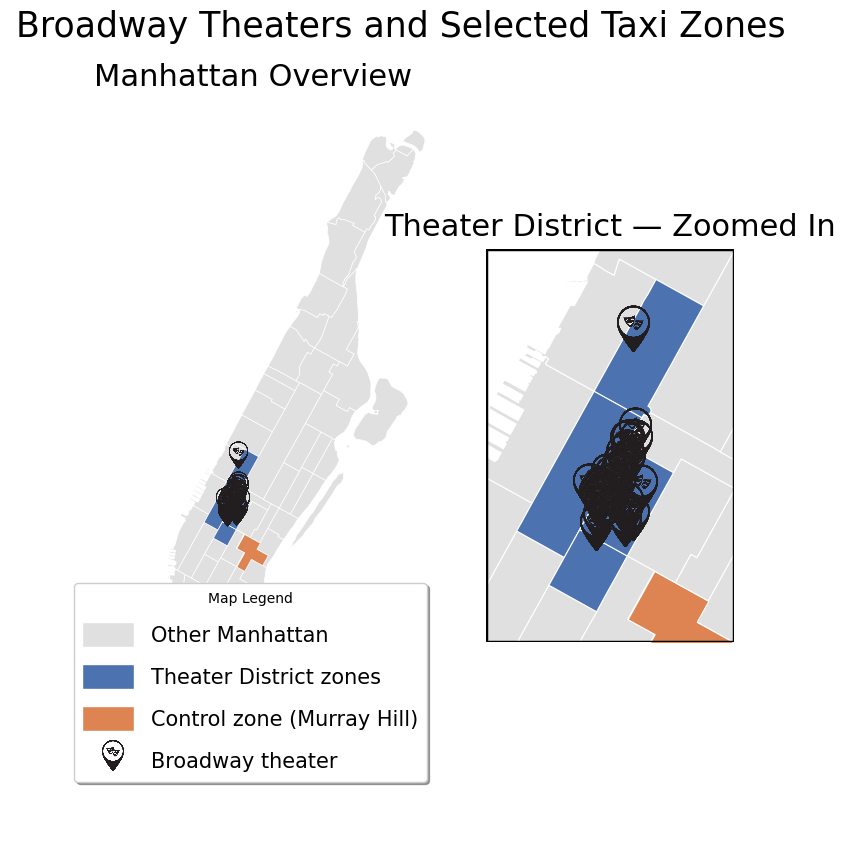

In [10]:


# --------------------------------------------------
# Create figure
# --------------------------------------------------

fig = plt.figure(figsize=(9, 9))

gs = fig.add_gridspec(
    1, 2,
    width_ratios=[1.4, 0.8],
    wspace=0.05
)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])


# --------------------------------------------------
# Colours
# --------------------------------------------------

colors = {
    "Other Manhattan": "#e0e0e0",
    "Theater District zones": "#4c72b0",
    "Control zone (Murray Hill)": "#dd8452"
}


# --------------------------------------------------
# Load theater PNG
# --------------------------------------------------

theater_icon = mpimg.imread(
    "../Theater_icon.png"
)


# ==================================================
# LEFT MAP — MANHATTAN OVERVIEW
# ==================================================

for label, color in colors.items():

    manhattan[
        manhattan["highlight"] == label
    ].plot(
        ax=ax1,
        color=color,
        edgecolor="white",
        linewidth=0.5
    )


# --------------------------------------------------
# Add theater PNG markers
# --------------------------------------------------

for _, row in theaters_gdf.iterrows():

    imagebox = OffsetImage(
        theater_icon,
        zoom=0.035
    )

    annotation = AnnotationBbox(
        imagebox,
        (row.geometry.x, row.geometry.y),
        xybox=(0, 10),
        boxcoords="offset points",
        frameon=False,
        zorder=5
    )

    ax1.add_artist(annotation)


ax1.set_title(
    "Manhattan Overview",
    fontsize=22,
    pad=10
)

ax1.set_axis_off()


# ==================================================
# RIGHT MAP — ZOOMED THEATER DISTRICT
# ==================================================

for label, color in colors.items():

    manhattan[
        manhattan["highlight"] == label
    ].plot(
        ax=ax2,
        color=color,
        edgecolor="white",
        linewidth=0.8
    )


# --------------------------------------------------
# Add theater PNG markers
# --------------------------------------------------

for _, row in theaters_gdf.iterrows():

    imagebox = OffsetImage(
        theater_icon,
        zoom=0.06
    )

    annotation = AnnotationBbox(
        imagebox,
        (row.geometry.x, row.geometry.y),
        xybox=(0, 15),
        boxcoords="offset points",
        frameon=False,
        zorder=5
    )

    ax2.add_artist(annotation)


# --------------------------------------------------
# Zoom into Theater District
# --------------------------------------------------

theater_zones = manhattan[
    manhattan["highlight"] == "Theater District zones"
]

minx, miny, maxx, maxy = theater_zones.total_bounds

padding = 1000

ax2.set_xlim(
    minx - padding,
    maxx + padding
)

ax2.set_ylim(
    miny - padding,
    maxy + padding
)


ax2.set_title(
    "Theater District — Zoomed In",
    fontsize=22,
    pad=10
)

ax2.set_axis_off()


# --------------------------------------------------
# Border around zoomed map
# --------------------------------------------------

rect = Rectangle(
    (0, 0),
    1,
    1,
    transform=ax2.transAxes,
    fill=False,
    edgecolor="black",
    linewidth=2.5,
    zorder=100
)

ax2.add_patch(rect)


# ==================================================
# LEGEND
# ==================================================

legend_handles = [

    Patch(
        facecolor=colors["Other Manhattan"],
        edgecolor="white",
        label="Other Manhattan"
    ),

    Patch(
        facecolor=colors["Theater District zones"],
        edgecolor="white",
        label="Theater District zones"
    ),

    Patch(
        facecolor=colors["Control zone (Murray Hill)"],
        edgecolor="white",
        label="Control zone (Murray Hill)"
    ),

    # Empty patch used only to create the
    # "Broadway theater" row
    Patch(
        facecolor="none",
        edgecolor="none",
        label="Broadway theater"
    )
]


legend = ax1.legend(
    handles=legend_handles,

    loc="lower left",

    fontsize=15,

    frameon=True,
    fancybox=True,
    shadow=True,

    title="Map Legend",

    handlelength=2.5,
    handleheight=1.5,
    labelspacing=0.8
)


# ==================================================
# PUT PNG INSIDE THE LEGEND
# ==================================================

# Make sure the figure has been drawn so that
# Matplotlib knows the legend's exact position.
fig.canvas.draw()


# Get legend bounding box in display coordinates
legend_bbox = legend.get_window_extent()


# Convert display coordinates to figure coordinates
legend_bbox_fig = legend_bbox.transformed(
    fig.transFigure.inverted()
)


# Position of the PNG inside the last legend row
x = 0.125
y = 0.095


# Create small PNG
imagebox = OffsetImage(
    theater_icon,
    zoom=0.04
)


# Place PNG using figure coordinates
png_annotation = AnnotationBbox(
    imagebox,
    (x, y),
    xycoords="figure fraction",
    frameon=False,
    box_alignment=(0.5, 0.5),
    zorder=1000
)


fig.add_artist(png_annotation)


# ==================================================
# OVERALL TITLE
# ==================================================

fig.text(
    0.53,
    0.98,
    "Broadway Theaters and Selected Taxi Zones",
    ha="center",
    va="top",
    fontsize=25
)


# --------------------------------------------------
# Layout
# --------------------------------------------------

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)


# --------------------------------------------------
# Save
# --------------------------------------------------

plt.savefig(
    "../plots/theater_district_map.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Map of pickup volume across all of Manhattan, for context.

26/08/31 19:05:16 WARN FileStreamSink: Assume no metadata directory. Error while looking for metadata directory in the path: ../data/yellow_taxi_data/2024-*.parquet.
java.io.FileNotFoundException: File ../data/yellow_taxi_data/2024-*.parquet does not exist
	at org.apache.hadoop.fs.RawLocalFileSystem.deprecatedGetFileStatus(RawLocalFileSystem.java:980)
	at org.apache.hadoop.fs.RawLocalFileSystem.getFileLinkStatusInternal(RawLocalFileSystem.java:1301)
	at org.apache.hadoop.fs.RawLocalFileSystem.getFileStatus(RawLocalFileSystem.java:970)
	at org.apache.hadoop.fs.FilterFileSystem.getFileStatus(FilterFileSystem.java:462)
	at org.apache.spark.sql.execution.streaming.sinks.FileStreamSink$.hasMetadata(FileStreamSink.scala:58)
	at org.apache.spark.sql.execution.datasources.DataSource.resolveRelation(DataSource.scala:394)
	at org.apache.spark.sql.catalyst.analysis.ResolveDataSource.org$apache$spark$sql$catalyst$analysis$ResolveDataSource$$loadV1BatchSource(ResolveDataSource.scala:210)
	at org.ap

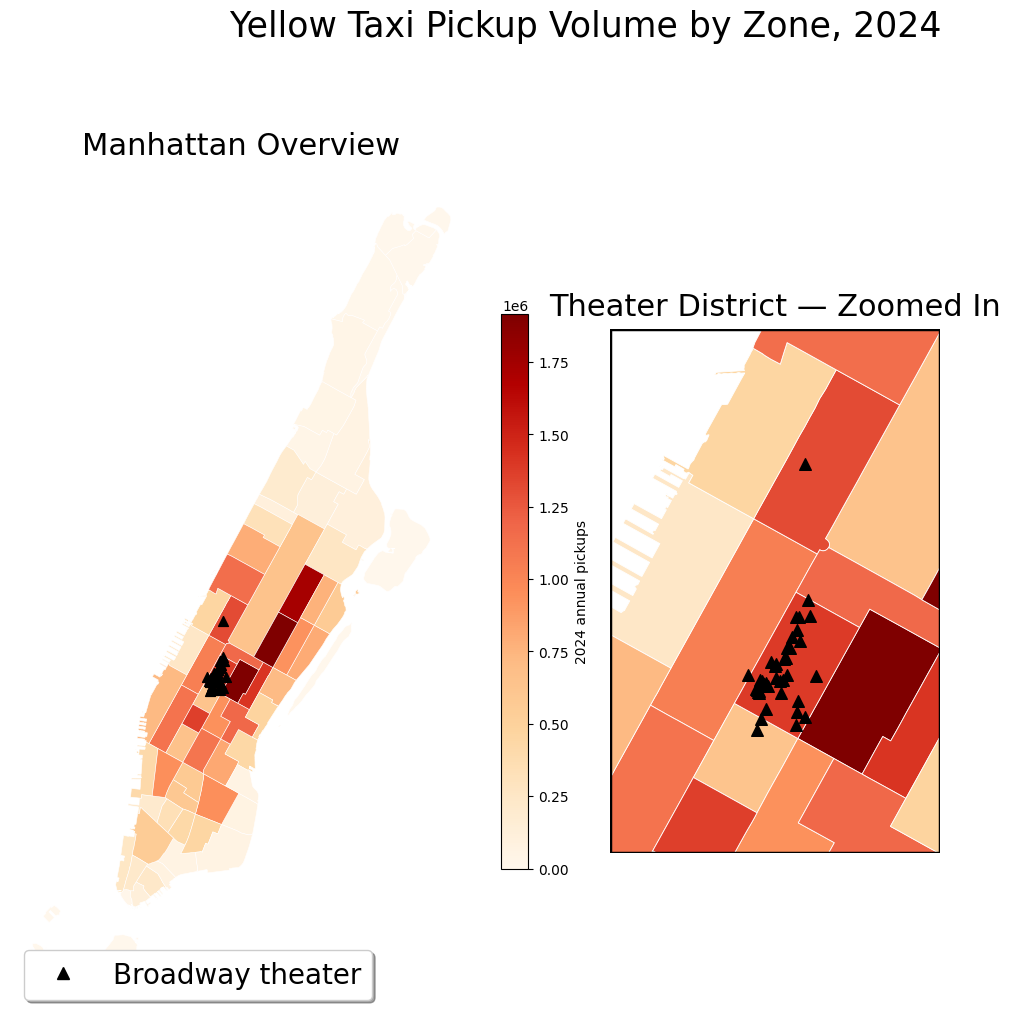

In [11]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D


# --------------------------------------------------
# Start Spark
# --------------------------------------------------

spark = SparkSession.builder.appName(
    "Geospatial"
).getOrCreate()


# --------------------------------------------------
# Load Yellow Taxi data
# --------------------------------------------------

all_yellow = spark.read.parquet(
    "../data/yellow_taxi_data/2024-*.parquet"
)


# --------------------------------------------------
# Calculate annual pickup totals
# --------------------------------------------------

zone_totals = (

    all_yellow

    .filter(
        (F.col("tpep_pickup_datetime") >= "2024-01-01") &
        (F.col("tpep_pickup_datetime") < "2025-01-01")
    )

    .groupBy("PULocationID")

    .agg(
        F.count("*").alias("annual_trips")
    )

    .toPandas()
)


# --------------------------------------------------
# Merge with Manhattan zones
# --------------------------------------------------

manhattan_totals = manhattan.merge(
    zone_totals,
    left_on="LocationID",
    right_on="PULocationID",
    how="left"
)

manhattan_totals["annual_trips"] = (
    manhattan_totals["annual_trips"].fillna(0)
)


# ==================================================
# CREATE SIDE-BY-SIDE MAPS
# ==================================================

fig = plt.figure(figsize=(12, 12))

gs = fig.add_gridspec(
    1, 2,
    width_ratios=[1.4, 0.8],
    wspace=0.05
)

ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])


# ==================================================
# LEFT MAP — MANHATTAN OVERVIEW
# ==================================================

manhattan_totals.plot(
    column="annual_trips",
    cmap="OrRd",
    legend=True,
    ax=ax1,
    edgecolor="white",
    linewidth=0.4,
    legend_kwds={
        "label": "2024 annual pickups",
        "shrink": 0.6
    }
)


# Add theater markers
theaters_gdf.plot(
    ax=ax1,
    color="black",
    markersize=50,
    marker="^",
    zorder=5
)


ax1.set_title(
    "Manhattan Overview",
    fontsize=22,
    pad=10
)

ax1.set_axis_off()


# ==================================================
# RIGHT MAP — THEATER DISTRICT ZOOM
# ==================================================

manhattan_totals.plot(
    column="annual_trips",
    cmap="OrRd",
    legend=False,
    ax=ax2,
    edgecolor="white",
    linewidth=0.6
)


# Add theater markers
theaters_gdf.plot(
    ax=ax2,
    color="black",
    markersize=70,
    marker="^",
    zorder=5
)


# --------------------------------------------------
# Zoom into Theater District
# --------------------------------------------------

theater_zones = manhattan[
    manhattan["highlight"] == "Theater District zones"
]

minx, miny, maxx, maxy = theater_zones.total_bounds

padding = 1000

ax2.set_xlim(
    minx - padding,
    maxx + padding
)

ax2.set_ylim(
    miny - padding,
    maxy + padding
)


ax2.set_title(
    "Theater District — Zoomed In",
    fontsize=22,
    pad=10
)

ax2.set_axis_off()


# --------------------------------------------------
# Border around zoomed map
# --------------------------------------------------

rect = Rectangle(
    (0, 0),
    1,
    1,
    transform=ax2.transAxes,
    fill=False,
    edgecolor="black",
    linewidth=2.5,
    zorder=100
)

ax2.add_patch(rect)


# ==================================================
# LEGEND FOR TAXI MAP
# ==================================================

theater_marker = Line2D(
    [0],
    [0],
    marker="^",
    color="black",
    markerfacecolor="black",
    markeredgecolor="black",
    markersize=8,
    linestyle="None",
    label="Broadway theater"
)


ax1.legend(
    handles=[theater_marker],
    loc="lower left",
    fontsize=20,
    frameon=True,
    fancybox=True,
    shadow=True
)


# --------------------------------------------------
# Overall title
# --------------------------------------------------

fig.text(
    0.6,
    0.98,
    " Yellow Taxi Pickup Volume by Zone, 2024",
    ha="center",
    va="top",
    fontsize=25
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)


plt.savefig(
    "../plots/manhattan_pickup_choropleth.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()